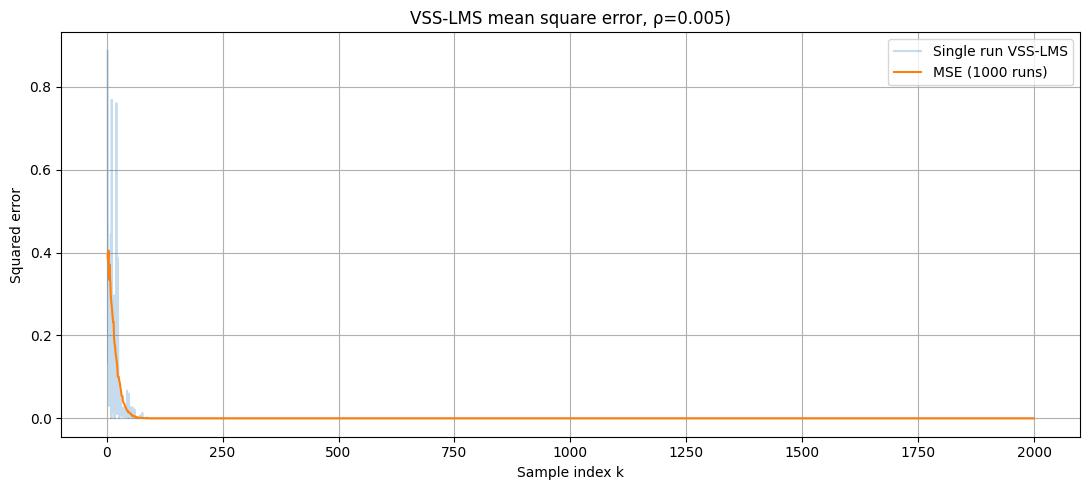

In [5]:

import numpy as np
import matplotlib.pyplot as plt

N = 2000
M = 3
R = 1000  # Number of independent runs

MU_init = 0.005
MU_max = 0.1111
MU_min = 0.00005
rho = 0.005

h = np.array([0.5, 0.25, -0.3])
seed = 11
noise_std = 1.0

rng = np.random.default_rng(seed)

# Store squared errors for all runs
error_squared_vss = np.zeros((R, N))

# Store histories for the first run
w_history = np.zeros((N, M))
mu_history = np.zeros((N, M))

for r in range(R):

    # New independent input for every run
    x = rng.normal(0, noise_std, N)
    d = np.convolve(x, h, mode="full")[:N]

    w = np.zeros(M)
    y = np.zeros(N)
    e = np.zeros(N)
    mu = np.full(M, MU_init)
    g_old = np.zeros(M)

    for k in range(M-1, N):
        x_vec = x[k-M+1:k+1][::-1]

        y[k] = np.dot(w, x_vec)
        e[k] = d[k] - y[k]

        # Store squared error
        error_squared_vss[r, k] = e[k]**2

        # Update tap weights and step sizes
        for i in range(M):

            g = e[k] * x[k-i]

            if k > M-1:
                mu[i] += rho * np.sign(g) * np.sign(g_old[i])

            mu[i] = np.clip(mu[i], MU_min, MU_max)

            w[i] += 2 * mu[i] * g

            g_old[i] = g

        # Save first run for plotting
        if r == 0:
            w_history[k] = w
            mu_history[k] = mu.copy()

# Mean square error across all runs
mse_vss = np.mean(error_squared_vss, axis=0)

# Plot
samples = np.arange(M-1, N)

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    samples,
    error_squared_vss[0, M-1:],
    label="Single run VSS-LMS",
    alpha=0.25
)

ax.plot(
    samples,
    mse_vss[M-1:],
    label=f"MSE ({R} runs)",
    linewidth=1.5
)

ax.set_xlabel("Sample index k")
ax.set_ylabel("Squared error")
ax.set_title(f"VSS-LMS mean square error, ρ={rho})")
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()
